# Келесі аптаның оқу белсенділігін болжау
**Тәжірибелік жұмыс 1.8 — Colab / Kaggle Notebook көмегімен зерттеу моделін әзірлеу**

**Зерттеу сұрағы (№5):** Алдыңғы екі аптадағы деректер бойынша келесі аптаның оқу белсенділігін болжауға бола ма?

| Элемент | Шешім |
|---|---|
| ML міндеті | Регрессия (қосымша: төмен белсенділік қаупін анықтау) |
| y (болжанатын нәтиже) | `active_minutes` — білім алушының **келесі (t+1) аптадағы** LMS-тегі белсенді минуттары |
| X (кіріс белгілері) | t және t−1 апталардағы: кіру саны, белсенді минут, бейне қарау, тапсырма тапсыру, форум хабарламасы, тест балы + өзгеріс (дельта), орта мән, бастапқы GPA, оқу күнтізбесі (келесі аптада дедлайн/демалыс бар ма) |
| Уақыт шекарасы | Болжам **t аптасының жексенбісінде** жасалады. X-те тек 1…t апталардың деректері, y — тек t+1 апта. Күнтізбе (дедлайн/демалыс) алдын ала белгілі, сондықтан деректердің ағуы (leakage) емес |
| Деректерді бөлу | Уақыт бойынша: оқыту — мақсатты апталар 3–12, валидация — 13–14, тест — 15–16 |
| Базалық модельдер | «Өткен аптадай болады» (naive) және «екі аптаның орташасы» |
| Негізгі модельдер | Ridge регрессия, Random Forest, HistGradientBoosting |
| Метрикалар | MAE (негізгі), RMSE, R²; қауіп үшін — Recall, Precision, F1 |

**Педагогикалық мағынасы:** келесі аптада белсенділігі күрт төмендейтін білім алушыларды алдын ала көріп, оқытушы/куратор ертерек хабарласа алады.

## 1. Ортаны дайындау
Colab-та барлық кітапханалар орнатулы. Kaggle / Deepnote / Binder үшін `requirements.txt` пайдаланылады. Нәтиже қайталанатын болуы үшін `SEED` бекітілген.

In [1]:
# Colab-та қажет болса: !pip install -q scikit-learn pandas matplotlib joblib
import os, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.13.17 | scikit-learn 1.9.1 | pandas 3.0.5


## 2. Деректер
Нақты LMS деректерін жариялау дербес деректер талаптарына байланысты шектеулі, сондықтан жұмыс **нақты LMS журналының құрылымын қайталайтын синтетикалық деректермен** орындалады: 300 білім алушы × 16 апта. Генератор мына заңдылықтарды ескереді: әр білім алушының тұрақты ынтасы, апта сайынғы кездейсоқ ауытқу (AR(1)), дедлайн апталарында белсенділіктің өсуі, демалыс аптасында түсуі, әлсіз білім алушылардың біртіндеп «сөнуі».

Сапаны тексеруді көрсету үшін деректерге әдейі ~3% бос мән, қайталанған жолдар және логтау қателері (шамадан тыс минуттар) енгізілді.

> Нақты деректер болса: `raw = pd.read_csv("сіздің_файл.csv")` — бағандар атауы төмендегі сөздікке сәйкес болса, қалған код өзгеріссіз жұмыс істейді.

In [2]:
DEADLINE_WEEKS = {4, 8, 12, 15}   # аралық бақылау / жоба тапсыру апталары
HOLIDAY_WEEKS = {10}              # демалыс аптасы
N_STUDENTS, N_WEEKS = 300, 16

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def generate_lms_data(n_students=N_STUDENTS, n_weeks=N_WEEKS, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for sid in range(1, n_students + 1):
        engagement = rng.normal(0, 1)                     # тұрақты ынта (бақыланбайды)
        prior_gpa = float(np.clip(3.0 + 0.4 * engagement + rng.normal(0, 0.35), 1.5, 4.0))
        group = rng.choice(["MT-25-1", "MT-25-2", "MT-25-3"])
        state = 0.0
        for w in range(1, n_weeks + 1):
            state = 0.6 * state + rng.normal(0, 0.5)       # апталық ауытқу
            fade = -0.04 * (w - 1) * (1.0 if engagement < 0 else 0.25)
            level = (0.6 * engagement + state + fade
                     + (0.35 if w in DEADLINE_WEEKS else 0)
                     + (-0.6 if w in HOLIDAY_WEEKS else 0))
            minutes = 150 * np.exp(0.45 * level) * rng.lognormal(0, 0.15)
            rows.append({
                "student_id": f"S{sid:03d}", "group": group, "week": w,
                "prior_gpa": round(prior_gpa, 2),
                "logins": int(rng.poisson(max(minutes / 25, 0.2))),
                "active_minutes": round(float(minutes), 1),
                "video_views": int(rng.poisson(minutes / 40)),
                "tasks_submitted": int(rng.binomial(3, sigmoid(0.8 * level + 0.8))),
                "forum_posts": int(rng.poisson(np.exp(0.5 * level - 0.8))),
                "quiz_score": round(float(np.clip(55 + 12 * engagement + 5 * state + rng.normal(0, 8), 0, 100)), 1),
            })
    df = pd.DataFrame(rows)
    # --- нақты журналға тән «кірлер» ---
    for col in ["active_minutes", "quiz_score"]:
        idx = rng.choice(len(df), size=int(0.03 * len(df)), replace=False)
        df.loc[idx, col] = np.nan
    bad = rng.choice(len(df), size=8, replace=False)          # логтау қатесі
    df.loc[bad, "active_minutes"] = rng.uniform(1500, 3000, size=8).round(1)
    df = pd.concat([df, df.sample(6, random_state=seed)], ignore_index=True)  # қайталанған жолдар
    return df

raw = generate_lms_data()
raw.to_csv("data/raw_weekly_activity.csv", index=False)
print(raw.shape)
raw.head()

(4806, 10)


,student_id,group,week,prior_gpa,logins,active_minutes,video_views,tasks_submitted,forum_posts,quiz_score
0,S001,MT-25-2,1,2.76,10,150.2,3,2,0,70.8
1,S001,MT-25-2,2,2.76,3,166.7,6,3,0,53.1
2,S001,MT-25-2,3,2.76,10,220.8,7,2,0,47.4
3,S001,MT-25-2,4,2.76,5,201.7,3,3,0,64.7
4,S001,MT-25-2,5,2.76,4,152.9,3,2,0,61.5


### 2.1 Деректер сөздігі

In [3]:
data_dictionary = pd.DataFrame([
    ("student_id", "мәтін", "Білім алушының анонимді коды", "—"),
    ("group", "санат", "Оқу тобы", "—"),
    ("week", "бүтін", "Семестр аптасы", "1–16"),
    ("prior_gpa", "нақты", "Алдыңғы семестрдің GPA", "1.5–4.0"),
    ("logins", "бүтін", "Аптадағы LMS-ке кіру саны", "≥0"),
    ("active_minutes", "нақты", "Аптадағы белсенді минуттар (y осы бағаннан алынады)", "0–900"),
    ("video_views", "бүтін", "Қаралған бейнесабақтар саны", "≥0"),
    ("tasks_submitted", "бүтін", "Тапсырылған тапсырмалар (аптасына 3-тен)", "0–3"),
    ("forum_posts", "бүтін", "Форумдағы хабарламалар", "≥0"),
    ("quiz_score", "нақты", "Апталық тесттің орташа балы", "0–100"),
], columns=["Баған", "Түрі", "Сипаттамасы", "Рұқсат етілген аралық"])
data_dictionary

,Баған,Түрі,Сипаттамасы,Рұқсат етілген аралық
0,student_id,мәтін,Білім алушының анонимді коды,—
1,group,санат,Оқу тобы,—
2,week,бүтін,Семестр аптасы,1–16
3,prior_gpa,нақты,Алдыңғы семестрдің GPA,1.5–4.0
4,logins,бүтін,Аптадағы LMS-ке кіру саны,≥0
5,active_minutes,нақты,Аптадағы белсенді минуттар (y осы бағаннан алы...,0–900
6,video_views,бүтін,Қаралған бейнесабақтар саны,≥0
7,tasks_submitted,бүтін,Тапсырылған тапсырмалар (аптасына 3-тен),0–3
8,forum_posts,бүтін,Форумдағы хабарламалар,≥0
9,quiz_score,нақты,Апталық тесттің орташа балы,0–100


### 2.2 Деректер сапасын тексеру және тазалау
Ережелер:
1. Толық қайталанған жолдар жойылады.
2. `active_minutes > 900` (аптасына 15 сағаттан көп) — логтау қатесі деп есептеліп, бос мәнге айналдырылады.
3. Бос мәндер **сол білім алушының** медианасымен толтырылады (басқа білім алушылардың деректері араласпайды).
4. Бастапқыда бос болған `active_minutes` жолдары **мақсат (y) ретінде пайдаланылмайды** — толтырылған мәнді болжау мағынасыз.

In [4]:
def quality_report(df):
    return pd.DataFrame({
        "бос_мән": df.isna().sum(),
        "бос_%": (df.isna().mean() * 100).round(2),
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
    })

print("Қайталанған жолдар:", raw.duplicated().sum())
print("Шамадан тыс минуттар (>900):", (raw["active_minutes"] > 900).sum())
quality_report(raw)

Қайталанған жолдар: 6
Шамадан тыс минуттар (>900): 9


,бос_мән,бос_%,min,max
active_minutes,144,3.0,30.1,2771.4
forum_posts,0,0.0,0.0,5.0
group,0,0.0,NaN,NaN
logins,0,0.0,0.0,41.0
prior_gpa,0,0.0,1.5,4.0
quiz_score,144,3.0,0.5,100.0
student_id,0,0.0,NaN,NaN
tasks_submitted,0,0.0,0.0,3.0
video_views,0,0.0,0.0,27.0
week,0,0.0,1.0,16.0


In [5]:
MAX_MINUTES = 900

def clean(df):
    df = df.drop_duplicates().copy()
    df.loc[df["active_minutes"] > MAX_MINUTES, "active_minutes"] = np.nan
    df["minutes_missing"] = df["active_minutes"].isna()
    for col in ["active_minutes", "quiz_score"]:
        df[col] = df[col].fillna(df.groupby("student_id")[col].transform("median"))
    return df.sort_values(["student_id", "week"]).reset_index(drop=True)

df = clean(raw)
df.to_csv("data/clean_weekly_activity.csv", index=False)
print("Тазалаудан кейін:", df.shape, "| қалған бос мән:", int(df.drop(columns='minutes_missing').isna().sum().sum()))
assert df.groupby("student_id")["week"].nunique().eq(N_WEEKS).all()

Тазалаудан кейін: (4800, 11) | қалған бос мән: 0


### 2.3 Барлау талдауы (EDA)

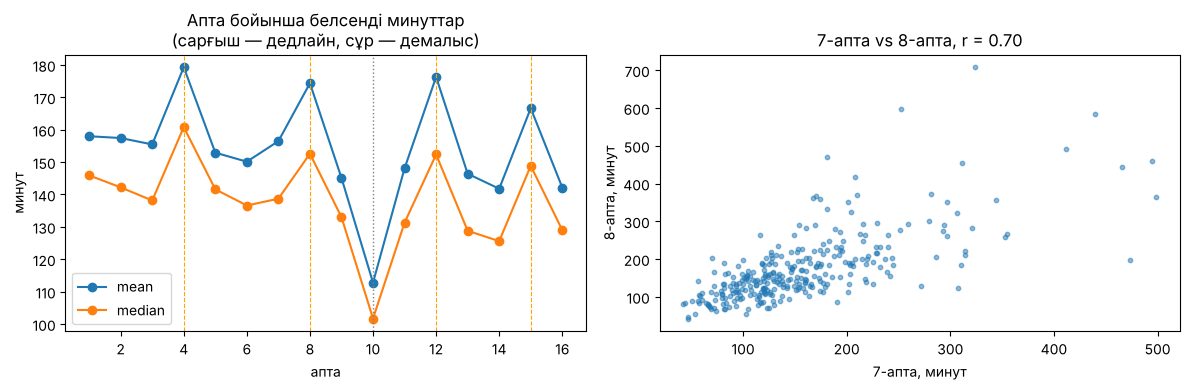

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
weekly = df.groupby("week")["active_minutes"].agg(["mean", "median"])
weekly.plot(ax=axes[0], marker="o")
for w in DEADLINE_WEEKS:
    axes[0].axvline(w, color="orange", ls="--", lw=0.8)
for w in HOLIDAY_WEEKS:
    axes[0].axvline(w, color="grey", ls=":", lw=1)
axes[0].set_title("Апта бойынша белсенді минуттар\n(сарғыш — дедлайн, сұр — демалыс)")
axes[0].set_xlabel("апта"); axes[0].set_ylabel("минут")

pivot = df.pivot(index="student_id", columns="week", values="active_minutes")
axes[1].scatter(pivot[7], pivot[8], s=10, alpha=0.5)
axes[1].set_title(f"7-апта vs 8-апта, r = {pivot[7].corr(pivot[8]):.2f}")
axes[1].set_xlabel("7-апта, минут"); axes[1].set_ylabel("8-апта, минут")
plt.tight_layout(); plt.savefig("outputs/eda.png", dpi=120); plt.show()

**Байқау:** белсенділік апталар арасында күшті корреляцияланған (өткен апта — жақсы бағдар), бірақ дедлайн мен демалыс апталарында жүйелі секірістер бар. Демек, күнтізбелік белгілер мен екі апталық динамика базалық «өткен аптадай» болжамнан жақсырақ нәтиже беруі мүмкін — осы гипотезаны тексереміз.

## 3. Белгілерді құрастыру (X / y)
Әр жол = (білім алушы, t апта). X — t және t−1 апталардың деректері, y — t+1 аптаның `active_minutes`. Сондықтан t = 2…15.

In [7]:
METRICS = ["logins", "active_minutes", "video_views", "tasks_submitted", "forum_posts", "quiz_score"]

def make_features(df):
    out = []
    for sid, g in df.groupby("student_id"):
        g = g.set_index("week")
        for t in range(2, N_WEEKS):
            cur, prev, nxt = g.loc[t], g.loc[t - 1], g.loc[t + 1]
            row = {"student_id": sid, "week_t": t, "target_week": t + 1,
                   "prior_gpa": cur["prior_gpa"]}
            for m in METRICS:
                row[f"{m}_w0"] = cur[m]          # t апта
                row[f"{m}_w1"] = prev[m]         # t-1 апта
            row["minutes_delta"] = cur["active_minutes"] - prev["active_minutes"]
            row["minutes_mean2"] = (cur["active_minutes"] + prev["active_minutes"]) / 2
            row["next_is_deadline"] = int((t + 1) in DEADLINE_WEEKS)
            row["next_is_holiday"] = int((t + 1) in HOLIDAY_WEEKS)
            row["y_next_minutes"] = nxt["active_minutes"]
            row["y_missing"] = nxt["minutes_missing"]
            out.append(row)
    return pd.DataFrame(out)

feat = make_features(df)
feat = feat[~feat["y_missing"]].drop(columns="y_missing").reset_index(drop=True)
FEATURES = [c for c in feat.columns if c not in ("student_id", "y_next_minutes", "target_week")]
TARGET = "y_next_minutes"
print("Жолдар:", len(feat), "| белгілер саны:", len(FEATURES))
print(FEATURES)

Жолдар: 4061 | белгілер саны: 18
['week_t', 'prior_gpa', 'logins_w0', 'logins_w1', 'active_minutes_w0', 'active_minutes_w1', 'video_views_w0', 'video_views_w1', 'tasks_submitted_w0', 'tasks_submitted_w1', 'forum_posts_w0', 'forum_posts_w1', 'quiz_score_w0', 'quiz_score_w1', 'minutes_delta', 'minutes_mean2', 'next_is_deadline', 'next_is_holiday']


### 3.1 Уақыт бойынша бөлу
Кездейсоқ бөлу болашақ апталардың деректерін оқытуға «ағызып» жібереді, сондықтан бөлу тек уақыт бойынша жасалады.

In [8]:
train = feat[feat["target_week"].between(3, 12)]
val   = feat[feat["target_week"].between(13, 14)]
test  = feat[feat["target_week"].between(15, 16)]
split_info = pd.DataFrame({
    "жиын": ["train", "validation", "test"],
    "мақсатты апталар": ["3–12", "13–14", "15–16"],
    "жолдар": [len(train), len(val), len(test)],
})
assert train["target_week"].max() < val["target_week"].min() <= val["target_week"].max() < test["target_week"].min()
split_info

,жиын,мақсатты апталар,жолдар
0,train,3–12,2902
1,validation,13–14,585
2,test,15–16,574


## 4. Базалық модельдер мен негізгі модельдер

In [9]:
def regression_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

baselines = {
    "Baseline: өткен апта": lambda d: d["active_minutes_w0"].values,
    "Baseline: 2 апта орташасы": lambda d: d["minutes_mean2"].values,
}
models = {
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                          max_leaf_nodes=15, random_state=SEED),
}

rows = []
for name, f in baselines.items():
    rows.append({"модель": name, **regression_metrics(val[TARGET], f(val))})
for name, m in models.items():
    m.fit(train[FEATURES], train[TARGET])
    rows.append({"модель": name, **regression_metrics(val[TARGET], m.predict(val[FEATURES]))})
val_results = pd.DataFrame(rows).sort_values("MAE").round(3)
val_results.to_csv("outputs/validation_results.csv", index=False)
val_results

,модель,MAE,RMSE,R2
2,Ridge,39.021,50.145,0.495
3,RandomForest,40.560,51.589,0.465
1,Baseline: 2 апта орташасы,42.425,58.084,0.322
4,HistGradientBoosting,42.679,55.396,0.384
0,Baseline: өткен апта,43.753,61.610,0.238


In [10]:
best_name = val_results[~val_results["модель"].str.startswith("Baseline")].iloc[0]["модель"]
print("Валидация бойынша ең жақсы модель:", best_name)

# Таңдалған модельді train + validation деректерінде қайта оқытып, тестте БІР рет бағалаймыз
from sklearn.base import clone
trainval = pd.concat([train, val])
final_model = clone(models[best_name]).fit(trainval[FEATURES], trainval[TARGET])
test_pred = final_model.predict(test[FEATURES])

test_rows = [{"модель": n, **regression_metrics(test[TARGET], f(test))} for n, f in baselines.items()]
test_rows.append({"модель": best_name + " (final)", **regression_metrics(test[TARGET], test_pred)})
test_results = pd.DataFrame(test_rows).round(3)
naive_mae = test_results.iloc[0]["MAE"]
test_results["базалықтан жақсару, %"] = ((naive_mae - test_results["MAE"]) / naive_mae * 100).round(1)
test_results.to_csv("outputs/test_results.csv", index=False)
test_results

Валидация бойынша ең жақсы модель: Ridge


,модель,MAE,RMSE,R2,"базалықтан жақсару, %"
0,Baseline: өткен апта,44.551,60.729,0.430,0.0
1,Baseline: 2 апта орташасы,40.348,56.083,0.514,9.4
2,Ridge (final),38.785,50.871,0.600,12.9


### 4.1 Педагогикалық көзқарас: «төмен белсенділік» қаупі
Оқытушыға нақты минуттан гөрі «кімге назар аудару керек?» деген сұрақ маңызды. Келесі аптада **90 минуттан аз** белсенділік — қауіп белгісі деп аламыз. Регрессия болжамын осы шекпен салыстырып, қауіпті тану сапасын бағалаймыз.

In [11]:
RISK_THRESHOLD = 90
TARGET_RECALL = 0.75

# Регрессия болжамды ортаға «тартады», сондықтан «болжам < 90» ережесі қауіптің көбін өткізіп алады.
# Шешім шегін (cutoff) ТЕК validation жиынында таңдаймыз: Recall ≥ 0.75 болатын ең кіші шек.
val_pred = models[best_name].predict(val[FEATURES])
y_val_risk = (val[TARGET] < RISK_THRESHOLD).astype(int)
CUTOFF = RISK_THRESHOLD
for c in np.arange(RISK_THRESHOLD, 200, 1.0):
    if recall_score(y_val_risk, (val_pred < c).astype(int)) >= TARGET_RECALL:
        CUTOFF = float(c); break
print(f"Validation бойынша таңдалған шешім шегі: болжам < {CUTOFF:.0f} минут → қауіп белгісі")

y_risk = (test[TARGET] < RISK_THRESHOLD).astype(int)
risk_rows = []
for name, pred, cut in [("Baseline: өткен апта", baselines["Baseline: өткен апта"](test), RISK_THRESHOLD),
                        (f"{best_name}, шек = 90", test_pred, RISK_THRESHOLD),
                        (f"{best_name}, шек = {CUTOFF:.0f} (validation)", test_pred, CUTOFF)]:
    p = (pred < cut).astype(int)
    risk_rows.append({"модель": name, "белгіленгендер": int(p.sum()),
                      "Precision": precision_score(y_risk, p),
                      "Recall": recall_score(y_risk, p), "F1": f1_score(y_risk, p)})
risk_results = pd.DataFrame(risk_rows).round(3)
risk_results.to_csv("outputs/risk_results.csv", index=False)
print(f"Тесттегі қауіп тобының үлесі: {y_risk.mean():.1%} ({y_risk.sum()} жол)")
risk_results

Validation бойынша таңдалған шешім шегі: болжам < 121 минут → қауіп белгісі
Тесттегі қауіп тобының үлесі: 20.6% (118 жол)


,модель,белгіленгендер,Precision,Recall,F1
0,Baseline: өткен апта,111,0.577,0.542,0.559
1,"Ridge, шек = 90",54,0.759,0.347,0.477
2,"Ridge, шек = 121 (validation)",148,0.595,0.746,0.662


**Түсіндірме:** шекті 90-да қалдырсақ, модель «сенімді» болғанымен (Precision жоғары) қауіп тобының көбін өткізіп алады. Оқытушы үшін қауіпті өткізіп алу артық хабарласудан қымбатырақ, сондықтан шек validation жиынында Recall ≈ 0.75 болатындай таңдалды. Бұл шек тест деректерін көрмей таңдалғандықтан, тесттегі нәтиже адал бағалау болып табылады.

## 5. Қате талдауы

In [12]:
err = test[["student_id", "week_t", "target_week", "prior_gpa", "active_minutes_w0",
            "minutes_mean2", "next_is_deadline", TARGET]].copy()
err["pred"] = test_pred.round(1)
err["abs_err"] = (err[TARGET] - err["pred"]).abs()
err["activity_level"] = pd.qcut(err["minutes_mean2"], 3, labels=["төмен", "орта", "жоғары"])

by_level = err.groupby("activity_level", observed=True)["abs_err"].agg(["count", "mean", "median"]).round(1)
by_week = err.groupby("target_week")["abs_err"].mean().round(1)
print("MAE белсенділік деңгейі бойынша:\n", by_level, "\n")
print("MAE мақсатты апта бойынша:\n", by_week)

MAE белсенділік деңгейі бойынша:
                 count  mean  median
activity_level                     
төмен             192  26.9    24.2
орта              192  36.4    32.6
жоғары            190  53.2    44.7 

MAE мақсатты апта бойынша:
 target_week
15    41.7
16    35.9
Name: abs_err, dtype: float64


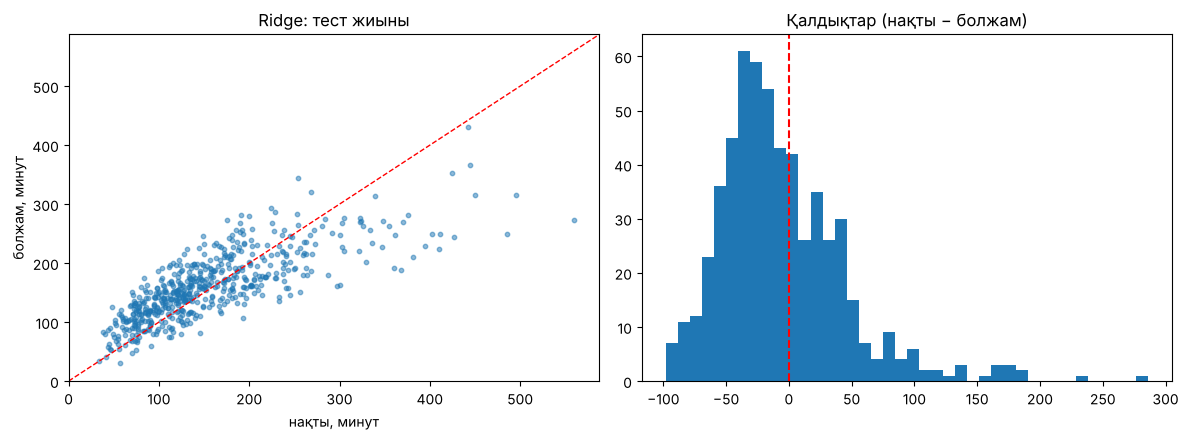

Ең үлкен 5 қате:


,student_id,week_t,target_week,prior_gpa,active_minutes_w0,minutes_mean2,next_is_deadline,y_next_minutes,pred,abs_err,activity_level
3058,S226,15,16,3.91,323.3,317.20,0,559.6,273.4,286.2,жоғары
804,S059,15,16,4.00,291.3,259.40,0,485.7,249.9,235.8,жоғары
1661,S122,14,15,2.94,240.9,215.75,1,410.1,224.6,185.5,жоғары
1730,S127,15,16,3.45,322.2,263.90,0,426.3,243.8,182.5,жоғары
3082,S228,14,15,3.45,125.0,162.70,1,367.8,187.8,180.0,орта


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(err[TARGET], err["pred"], s=10, alpha=0.5)
lim = [0, max(err[TARGET].max(), err["pred"].max()) * 1.05]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("нақты, минут"); axes[0].set_ylabel("болжам, минут")
axes[0].set_title(f"{best_name}: тест жиыны")
resid = err[TARGET] - err["pred"]
axes[1].hist(resid, bins=40)
axes[1].axvline(0, color="r", ls="--")
axes[1].set_title("Қалдықтар (нақты − болжам)")
plt.tight_layout(); plt.savefig("outputs/errors.png", dpi=120); plt.show()

print("Ең үлкен 5 қате:")
err.sort_values("abs_err", ascending=False).head(5)

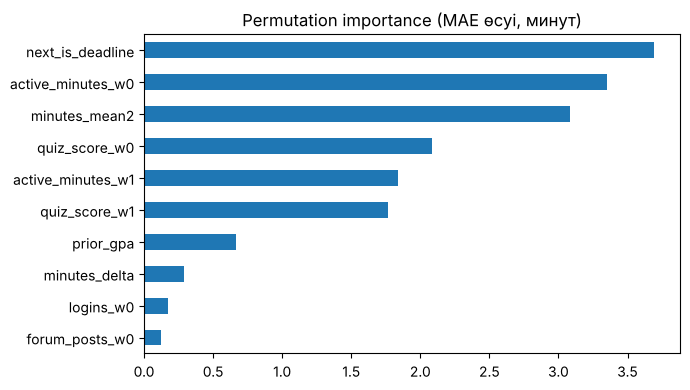

In [14]:
pi = permutation_importance(final_model, test[FEATURES], test[TARGET], n_repeats=10,
                            random_state=SEED, scoring="neg_mean_absolute_error")
importance = (pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=True).tail(10))
importance.plot(kind="barh", figsize=(7, 4), title="Permutation importance (MAE өсуі, минут)")
plt.tight_layout(); plt.savefig("outputs/importance.png", dpi=120); plt.show()

**Қате талдауының қорытындысы** (нақты сандар жоғарыдағы шығысқа сәйкес):
- Абсолютті қате белсенділігі жоғары білім алушыларда үлкенірек (төмен топта ~27 минут, жоғары топта ~53 минут): минут шкаласында ауытқулар белсенділікке пропорционал.
- Модель жоғары мәндерді жүйелі түрде **төмен бағалайды** (шашырау графигінде нүктелер диагональдан төмен): сызықтық Ridge болжамды ортаға тартады. Жақсарту жолы — y-ті логарифмдеу немесе квантильдік регрессия.
- Ең үлкен қателер — кенеттен «құлаған» немесе «секірген» апталар (ауру, жеке себеп): мұндай оқиғалар белгілерде жоқ, сондықтан оларды ешбір модель алдын ала көре алмайды.
- Ең маңызды белгілер — соңғы аптаның белсенділігі және келесі аптадағы дедлайн/демалыс: модель күнтізбені ескеруі арқасында базалық болжамнан озады.

## 6. Модельді және нәтижелерді сақтау

In [15]:
MODEL_PATH = "models/activity_model.joblib"
joblib.dump(final_model, MODEL_PATH)
best_test = test_results.iloc[-1]
metadata = {
    "research_question": "Алдыңғы екі аптадағы деректер бойынша келесі аптаның оқу белсенділігін болжау",
    "model": best_name,
    "features": FEATURES,
    "target": "next week active_minutes",
    "split": {"train_target_weeks": "3-12", "val_target_weeks": "13-14", "test_target_weeks": "15-16"},
    "test_metrics": {"MAE": float(best_test["MAE"]), "RMSE": float(best_test["RMSE"]), "R2": float(best_test["R2"])},
    "baseline_test_MAE": float(naive_mae),
    "risk_threshold_minutes": RISK_THRESHOLD,
    "risk_cutoff_on_prediction": CUTOFF,
    "deadline_weeks": sorted(DEADLINE_WEEKS), "holiday_weeks": sorted(HOLIDAY_WEEKS),
    "sklearn_version": sklearn.__version__, "seed": SEED,
}
with open("models/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
err.to_csv("outputs/test_predictions.csv", index=False)

# Тексеру: сақталған модель қайта жүктеліп, сол болжамды береді
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(test[FEATURES]), test_pred)
print("Сақталды:", MODEL_PATH, "| metadata:", metadata["test_metrics"])

Сақталды: models/activity_model.joblib | metadata: {'MAE': 38.785, 'RMSE': 50.871, 'R2': 0.6}


### 6.1 Бұлтта сақтау (Google Drive)
Colab-та орындағанда төмендегі ұяшық `models/`, `outputs/`, `data/` қалталарын Drive-қа көшіреді. Colab-тан тыс ортада ол өткізіліп жіберіледі.

In [16]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DEST = "/content/drive/MyDrive/activity_forecast"
    os.makedirs(DEST, exist_ok=True)
    import shutil
    for folder in ["models", "outputs", "data"]:
        shutil.copytree(folder, f"{DEST}/{folder}", dirs_exist_ok=True)
    print("Google Drive-қа сақталды:", DEST)
except ImportError:
    print("Colab емес орта — Drive-қа сақтау өткізілді (файлдар жергілікті қалада).")

Colab емес орта — Drive-қа сақтау өткізілді (файлдар жергілікті қалада).


## 7. GitHub → Streamlit
1. GitHub-та `activity-forecast` репозиторийін ашып, мына файлдарды жүктеңіз: `activity_forecast.ipynb`, `app.py`, `requirements.txt`, `models/`, `data/`, `README.md`.
2. [share.streamlit.io](https://share.streamlit.io) → **New app** → репозиторий, `main` тармағы, `app.py` → **Deploy**.
3. Алынған сілтемені есепке қосыңыз.

**Binder:** `https://mybinder.org/v2/gh/<username>/activity-forecast/HEAD?labpath=activity_forecast.ipynb` — notebook-ті басқа адам орнатусыз қайта іске қосып тексере алады.
**Deepnote:** New project → Import from GitHub → `requirements.txt` автоматты орнатылады.

## 8. Қорытынды және шектеулер
- **Жауап:** Иә, бірақ шектеулі дәлдікпен. Екі аптаның деректерімен оқытылған Ridge моделі тест жиынында «өткен аптадай болады» базалық болжамынан дәлірек (MAE, RMSE және R² бойынша — нақты сандар 4-бөлімде). Модель жеке білім алушының келесі аптасын минутқа дейін дәл айтпайды, бірақ «қауіп тобын» ерте белгілеуге жарамды.
- **Шектеулер:** деректер синтетикалық — нақты LMS журналында нәтиже төмен болуы мүмкін; жеке оқиғалар (ауру, отбасылық жағдай) белгілерде жоқ; бір пән, бір семестр; модель себепті емес, корреляциялық байланысты көрсетеді.
- **Этика:** болжам — оқытушыға көмекші сигнал, білім алушыны бағалау немесе жазалау құралы емес; деректер анонимделуі тиіс.
- **Келесі қадам:** нақты LMS (Moodle/Platonus) деректерінде қайталау, жаңа (оқытуда болмаған) білім алушылардағы тексеру, сенімділік аралығын шығару.